# Idea 12b - Repair

**Rebuilds Figures 2, 3, 4 and 5 and the payload for Idea 12.**

The first run produced one sound figure and three broken ones. The code lists
came back empty from the Census metadata endpoint, so every label fell back to
a raw numeric code and the class selections were made by sorting those codes.
Three things followed:

1. **Code 1 is the Total.** It landed in the small-firm group and in the
   young-firm group, so those shares were measuring the total against itself.
2. **BDS publishes subtotals in the same dimension as their components.** Codes
   635, 650 and 657 are aggregates of the other size classes, so the
   denominator summed to roughly three times the right number.
3. **The age comparison began in 1978**, the first year of BDS, when the age of
   every existing firm is unknown and sits in a left-censored class holding 93
   percent of employment.

The age reconciliation caught it, at a gap of 152 percent. It was a warning
rather than a stop, and it ran only on the age breakdown. Both were mistakes.

### How this fixes it

Without labels, which matters because the metadata endpoint is unreachable from
here. A partition is identifiable from arithmetic alone: **it is the largest
set of classes that sums to the national total in every year.** Everything else
in the dimension is a total or a subtotal. That test now runs on every
breakdown before anything downstream uses it, and it raises rather than warns.

### What this notebook costs

Nothing to re-fetch for Sections A, B, C and E, which read the cache written by
the first run. Section D makes at most six calls, and only for two years, since
a shift-share needs a start and an end rather than the whole series.

In [1]:
import importlib, itertools, json, pathlib, sys, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("12_dynamism_and_concentration", start=ROOT)
KEYS = sl.load_keys()
CENSUS = sl.require(KEYS, "CENSUS")

sl.apply_theme()
pd.set_option("display.width", 180)
BDS = "https://api.census.gov/data/timeseries/bds"

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## Load what the first run already fetched

These four files are the cache from the original notebook. Nothing here calls
the API, so a rerun is free and cannot fail on the network.

In [2]:
DATA = pathlib.Path(DIRS["data"])

def cached(name):
    p = DATA / name
    if not p.exists():
        raise FileNotFoundError(
            "%s is missing. Run the fetch cells of 12_dynamism_and_concentration "
            "first; this notebook only repairs what that one downloaded." % p)
    df = pd.read_csv(p)
    print("  %-28s %5d rows, %d-%d" % (name, len(df), df["year"].min(), df["year"].max()))
    return df

print("reading cache:")
nat = cached("bds_national.csv")
size = cached("bds_by_firmsize.csv")
age = cached("bds_by_age.csv")

N = nat.set_index("year").sort_index()
size["EMPSZFI"] = size["EMPSZFI"].astype(str)
age["FAGE"] = age["FAGE"].astype(str)
ENTRY, EXIT = N.get("ESTABS_ENTRY_RATE"), N.get("ESTABS_EXIT_RATE")
NAT = N["EMP"]
print("\nnational employment %s (%d) -> %s (%d)"
      % (f"{NAT.iloc[0]:,.0f}", NAT.index[0], f"{NAT.iloc[-1]:,.0f}", NAT.index[-1]))

reading cache:
  bds_national.csv                46 rows, 1978-2023
  bds_by_firmsize.csv            644 rows, 1978-2023
  bds_by_age.csv                 690 rows, 1978-2023

national employment 70,255,157 (1978) -> 137,462,444 (2023)


## The partition test

This is the general fix and it belongs in stacklib after this notebook. It
needs no labels, no metadata endpoint and no knowledge of the dataset's
conventions.

In [4]:
def _sortkey(c):
    """Numeric codes sort by value; anything else sorts as text."""
    s = str(c)
    return (0, int(s), "") if s.lstrip("-").isdigit() else (1, 0, s)


def finest_partition(frame, national, tol=0.002, name=""):
    """
    Largest subset of columns summing to `national` in every year. Prints what it
    kept and what it dropped, and raises rather than guessing if nothing sums.
    """
    cols = [c for c in frame.columns if frame[c].notna().any()]
    n = national.reindex(frame.index)
    exact = [c for c in cols if (frame[c] / n - 1).abs().max() < 1e-6]
    rest = [c for c in cols if c not in exact]
    best = None
    for r in range(len(rest), 1, -1):
        for combo in itertools.combinations(rest, r):
            if (frame[list(combo)].sum(axis=1) / n - 1).abs().max() < tol:
                best = list(combo)
                break
        if best:
            break
    if best is None:
        raise LookupError("%s: no subset of classes sums to the national total. "
                          "Classes present: %s" % (name, cols))
    dropped = [c for c in cols if c not in best]
    gap = ((frame[best].sum(axis=1) / n - 1) * 100).abs().max()
    print("%s: kept %d classes, dropped %d as totals or subtotals"
          % (name, len(best), len(dropped)))
    print("   kept:    %s" % sorted(best, key=_sortkey))
    print("   dropped: %s  (exactly equal to the total: %s)"
          % (sorted(dropped, key=_sortkey), exact))
    print("   worst reconciliation gap: %.4f%%" % gap)
    return best, gap


# The test itself, checked on constructed data before it is trusted.
_yrs = list(range(2000, 2011))
_true = pd.DataFrame({("c%d" % i): np.linspace(10 + i, 20 + i, len(_yrs)) for i in range(4)},
                     index=_yrs)
_nat = _true.sum(axis=1)
_probe = _true.copy()
_probe["TOTAL"] = _nat                       # a total in disguise
_probe["SUB01"] = _true[["c0", "c1"]].sum(axis=1)   # a subtotal
_got, _gap = finest_partition(_probe, _nat, name="synthetic check")
assert set(_got) == set(_true.columns) and _gap < 1e-9
print("   planted partition recovered exactly  ok\n")

synthetic check: kept 4 classes, dropped 2 as totals or subtotals
   kept:    ['c0', 'c1', 'c2', 'c3']
   dropped: ['SUB01', 'TOTAL']  (exactly equal to the total: ['TOTAL'])
   worst reconciliation gap: 0.0000%
   planted partition recovered exactly  ok



## Section B, rebuilt: where the employment sits

In [5]:
EMPBY_ALL = size.pivot_table(index="year", columns="EMPSZFI", values="EMP", aggfunc="sum")
EMPBY_ALL.columns = EMPBY_ALL.columns.astype(str)
PSZ, SZ_GAP = finest_partition(EMPBY_ALL, NAT, name="EMPSZFI")

EMPBY = EMPBY_ALL[sorted(PSZ, key=lambda c: int(c))]
SHARE = EMPBY.div(EMPBY.sum(axis=1), axis=0) * 100

# Codes ascend with firm size, so the partition sorted numerically is ordered.
ORDER = list(EMPBY.columns)
BIG, SMALL = ORDER[-2:], ORDER[:3]
BIGSHARE, SMALLSHARE = SHARE[BIG].sum(axis=1), SHARE[SMALL].sum(axis=1)
print("\nlargest two classes %s: %.2f%% -> %.2f%%   %+.2f points"
      % (BIG, BIGSHARE.iloc[0], BIGSHARE.iloc[-1], BIGSHARE.iloc[-1] - BIGSHARE.iloc[0]))
print("smallest three %s: %.2f%% -> %.2f%%   %+.2f points"
      % (SMALL, SMALLSHARE.iloc[0], SMALLSHARE.iloc[-1], SMALLSHARE.iloc[-1] - SMALLSHARE.iloc[0]))

def class_hhi(counts):
    s = counts / counts.sum()
    return float((s ** 2).sum())
print("class HHI (%d classes, a bound not an estimate): %.4f -> %.4f"
      % (len(ORDER), class_hhi(EMPBY.iloc[0]), class_hhi(EMPBY.iloc[-1])))
print("\nemployment share by class, first and last year:")
print(SHARE.iloc[[0, -1]].round(2).to_string())

EMPSZFI: kept 10 classes, dropped 4 as totals or subtotals
   kept:    ['612', '620', '630', '640', '649', '658', '661', '671', '672', '680']
   dropped: ['1', '635', '650', '657']  (exactly equal to the total: ['1'])
   worst reconciliation gap: 0.0000%

largest two classes ['672', '680']: 30.16% -> 35.69%   +5.53 points
smallest three ['612', '620', '630']: 22.72% -> 16.69%   -6.03 points
class HHI (10 classes, a bound not an estimate): 0.1406 -> 0.1572

employment share by class, first and last year:
EMPSZFI   612   620   630    640    649   658   661   671   672    680
year                                                                  
1978     7.55  7.03  8.14  18.06  12.88  4.92  6.43  4.84  5.15  25.01
2023     5.25  5.00  6.44  16.07  13.46  5.31  7.19  5.58  5.79  29.90


saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig2_employment_by_size.png


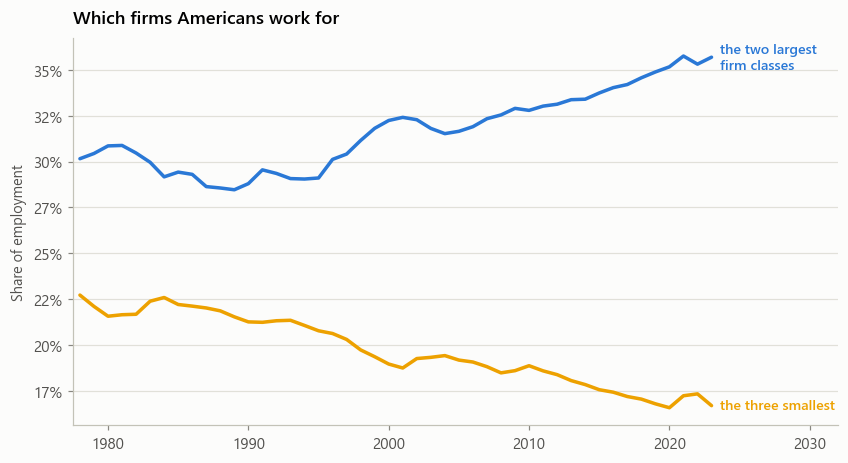

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 4.1))
ax.plot(BIGSHARE.index, BIGSHARE.values, color=sl.PALETTE[0], lw=2.3)
ax.plot(SMALLSHARE.index, SMALLSHARE.values, color=sl.PALETTE[3], lw=2.3)
ax.text(BIGSHARE.index[-1] + 0.6, BIGSHARE.iloc[-1], "the two largest\nfirm classes",
        color=sl.PALETTE[0], fontsize=9.3, va="center", fontweight="semibold", linespacing=1.3)
ax.text(SMALLSHARE.index[-1] + 0.6, SMALLSHARE.iloc[-1], "the three smallest",
        color=sl.PALETTE[3], fontsize=9.3, va="center", fontweight="semibold")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
ax.set_ylabel("Share of employment")
ax.set_xlim(SHARE.index.min() - 0.5, SHARE.index.max() + 9)
ax.set_title("Which firms Americans work for")
sl.save_fig(fig, "fig2_employment_by_size", DIRS)
plt.show()

## Section C, rebuilt: the headline

Two panels sharing one time axis. The quantities have different units, and two
vertical scales on one chart is how a comparison gets made to look like
whatever the author wanted.

saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig3_dynamism_and_concentration.png


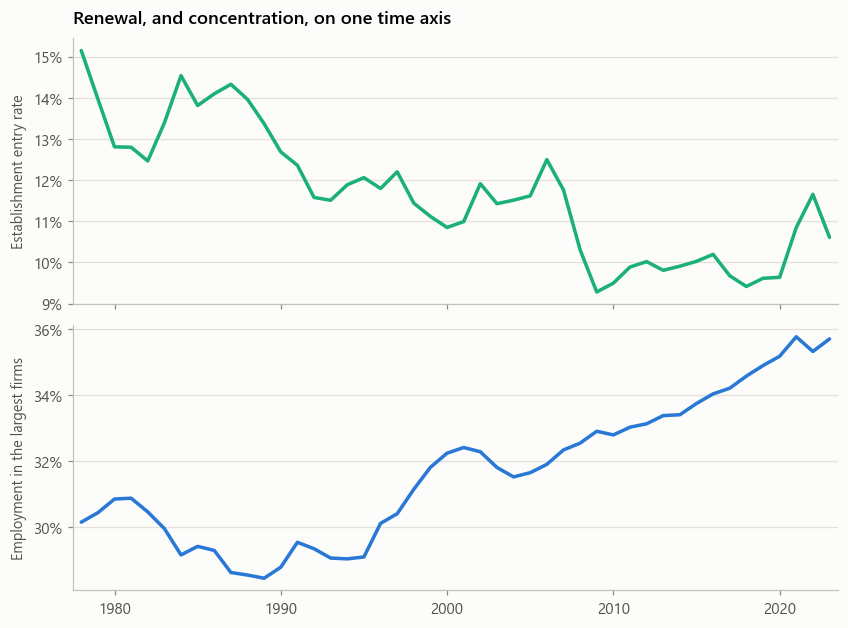

correlation between entry rate and large-firm share: -0.770 over 46 years
Two trending series. Idea 3 showed a correlation like this can mean nothing. Reported as description, not inference.


In [7]:
if ENTRY is None:
    print("WARNING  ESTABS_ENTRY_RATE is not in the cache; Figure 3 skipped.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.6), sharex=True)
    axes[0].plot(ENTRY.index, ENTRY.values, color=sl.PALETTE[2], lw=2.3)
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    axes[0].set_ylabel("Establishment entry rate")
    axes[0].set_title("Renewal, and concentration, on one time axis")
    axes[1].plot(BIGSHARE.index, BIGSHARE.values, color=sl.PALETTE[0], lw=2.3)
    axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    axes[1].set_ylabel("Employment in the largest firms")
    axes[1].set_xlim(N.index.min() - 0.5, N.index.max() + 0.5)
    sl.save_fig(fig, "fig3_dynamism_and_concentration", DIRS)
    plt.show()

    both = pd.DataFrame({"entry": ENTRY, "big_share": BIGSHARE}).dropna()
    print("correlation between entry rate and large-firm share: %.3f over %d years"
          % (both["entry"].corr(both["big_share"]), len(both)))
    print("Two trending series. Idea 3 showed a correlation like this can mean "
          "nothing. Reported as description, not inference.")

## Section E, rebuilt: how much of the economy is new

BDS begins in 1978, so no firm can be observed at age four before 1982, and
every firm that already existed sits in a left-censored class. Shares before
1982 are not comparable with later ones, and the series starts there.

In [8]:
A_ALL = age.pivot_table(index="year", columns="FAGE", values="EMP", aggfunc="sum")
A_ALL.columns = A_ALL.columns.astype(str)
PAG, AG_GAP = finest_partition(A_ALL, NAT, name="FAGE")

AGE_START = 1982
first = A_ALL.index.min()
shares_first = A_ALL[PAG].loc[first] / A_ALL[PAG].loc[first].sum() * 100
print("\nin %d the largest age class is %s, holding %.1f%% of employment"
      % (first, shares_first.idxmax(), shares_first.max()))
print("that is the left-censored class; age shares therefore start at %d" % AGE_START)

ORDER_AGE = sorted(PAG, key=lambda c: int(c))
YOUNG = ORDER_AGE[:5]                     # ages 0 to 4
print("young classes (ages 0 to 4): %s" % YOUNG)

def age_share(measure):
    if measure not in age.columns:
        print("  %s not in the cache; skipped." % measure)
        return None
    F = age.pivot_table(index="year", columns="FAGE", values=measure, aggfunc="sum")
    F.columns = F.columns.astype(str)
    cols = [c for c in PAG if c in F.columns]
    s = (F[YOUNG].sum(axis=1) / F[cols].sum(axis=1) * 100).dropna()
    return s[s.index >= AGE_START]

summary = pd.DataFrame({k: v for k, v in {
    "share of firms": age_share("FIRM"),
    "share of employment": age_share("EMP"),
    "share of job creation": age_share("JOB_CREATION"),
}.items() if v is not None})

assert len(summary.columns), "no age measure resolved; check the cache columns."
for k in summary.columns:
    s = summary[k].dropna()
    assert s.between(0, 100).all(), (k, s.min(), s.max())
print()
for k in summary.columns:
    s = summary[k].dropna()
    print("  %-22s %.2f%% (%d) -> %.2f%% (%d)   %+.2f points   peak %.2f%% in %d"
          % (k, s.iloc[0], s.index[0], s.iloc[-1], s.index[-1],
             s.iloc[-1] - s.iloc[0], s.max(), s.idxmax()))

FAGE: kept 12 classes, dropped 3 as totals or subtotals
   kept:    ['10', '20', '30', '40', '50', '60', '70', '80', '90', '100', '110', '150']
   dropped: ['1', '65', '75']  (exactly equal to the total: ['1'])
   worst reconciliation gap: 0.0000%

in 1978 the largest age class is 150, holding 93.0% of employment
that is the left-censored class; age shares therefore start at 1982
young classes (ages 0 to 4): ['10', '20', '30', '40', '50']

  share of firms         39.21% (1982) -> 31.93% (2023)   -7.28 points   peak 40.96% in 1987
  share of employment    13.50% (1982) -> 8.94% (2023)   -4.56 points   peak 15.92% in 1988
  share of job creation  35.28% (1982) -> 24.40% (2023)   -10.88 points   peak 37.28% in 1987


saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig5_young_firms.png


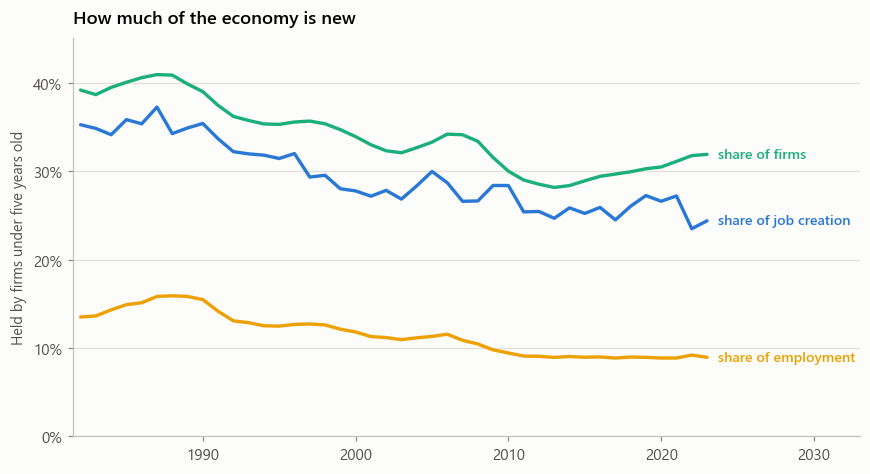

In [9]:
cols = {"share of firms": sl.PALETTE[2], "share of employment": sl.PALETTE[3],
        "share of job creation": sl.PALETTE[0]}
fig, ax = plt.subplots(figsize=(7.8, 4.2))
tails = sorted(((summary[k].dropna().iloc[-1], k) for k in summary.columns), reverse=True)
nudge = {k: 0.0 for _, k in tails}
for i in range(1, len(tails)):
    if tails[i - 1][0] + nudge[tails[i - 1][1]] - tails[i][0] < 2.4:
        nudge[tails[i][1]] = nudge[tails[i - 1][1]] - 2.4
for k in summary.columns:
    s = summary[k].dropna()
    ax.plot(s.index, s.values, color=cols[k], lw=2.2)
    ax.text(s.index[-1] + 0.7, s.iloc[-1] + nudge[k], k, color=cols[k],
            fontsize=9.3, va="center", fontweight="semibold")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
ax.set_ylabel("Held by firms under five years old")
ax.set_xlim(summary.index.min() - 0.5, summary.index.max() + 10)
ax.set_ylim(0, max(45, summary.max().max() * 1.1))
ax.set_title("How much of the economy is new")
sl.save_fig(fig, "fig5_young_firms", DIRS)
plt.show()

## Section D, re-issued

The original sector query returned a single code, 0, meaning all sectors, so
the decomposition had one sector and returned exactly zero for the between and
interaction terms. BDS carries industry detail on NAICS with an INDLEVEL
parameter rather than on SECTOR alone. Rather than assume which form works,
try each and keep the first that returns more than one industry.

In [10]:
def bds_query(get_list, extra, years, tag):
    """Cached fetcher for the two probe years only."""
    cache = DATA / ("%s.csv" % tag)
    if cache.exists():
        print("  reading cache %s" % cache.name)
        return pd.read_csv(cache)
    frames = []
    for y in years:
        q = {"get": get_list, "for": "us:*", "YEAR": str(y), "key": CENSUS}
        q.update(extra)
        r = requests.get(BDS, params=q, timeout=120)
        if r.status_code != 200:
            raise RuntimeError("%s: %s" % (r.status_code, r.text[:160]))
        rows = r.json()
        frames.append(pd.DataFrame(rows[1:], columns=rows[0]))
        time.sleep(0.2)
    df = pd.concat(frames, ignore_index=True)
    for c in df.columns:
        conv = pd.to_numeric(df[c], errors="coerce")
        if conv.notna().all():
            df[c] = conv
    df = df.rename(columns={"YEAR": "year"})
    df.to_csv(cache, index=False)
    return df


def fetch_industry_size():
    probe_years = [int(N.index.min()), int(N.index.max())]
    attempts = [
        ("SECTOR with INDLEVEL=2", "EMP,EMPSZFI,SECTOR", {"INDLEVEL": "2"}, "bds_ind_sector2"),
        ("NAICS with INDLEVEL=2", "EMP,EMPSZFI,NAICS", {"INDLEVEL": "2"}, "bds_ind_naics2"),
        ("NAICS alone", "EMP,EMPSZFI,NAICS", {}, "bds_ind_naics"),
    ]
    for label, get_list, extra, tag in attempts:
        try:
            df = bds_query(get_list, extra, probe_years, tag)
        except Exception as e:
            print("  %-26s failed: %s" % (label, str(e)[:100]))
            continue
        col = "SECTOR" if "SECTOR" in df.columns else "NAICS"
        vals = sorted(df[col].astype(str).unique())
        print("  %-26s %d industries: %s" % (label, len(vals), vals[:12]))
        if len(vals) > 1:
            return df.rename(columns={col: "IND"}), label
    return None, None

print("probing for an industry breakdown:")
ind, how = fetch_industry_size()
SECTOR_OK = ind is not None
Y0 = Y1 = within = between = cross = total = None
if not SECTOR_OK:
    print("\nNo query returned more than one industry. Section D stays withdrawn, "
          "and the write-up says the decomposition could not be run.")

probing for an industry breakdown:
  SECTOR with INDLEVEL=2     1 industries: ['0']
  NAICS with INDLEVEL=2      20 industries: ['00', '11', '21', '22', '23', '31-33', '42', '44-45', '48-49', '51', '52', '53']


industries present in both 1978 and 2023: 20
decomposition identity holds: +5.5344 == +5.5344
  within industries   +5.89
  between industries  -3.19
  interaction         +2.83
  total               +5.53
saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig4_shift_share.png


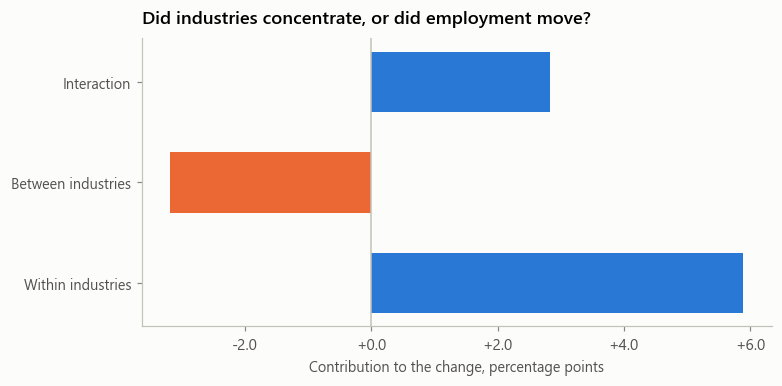


industries where the large-firm share rose most:
IND
44-45    28.34
62       26.55
56       22.51
48-49    17.94
52       16.81
53       12.47
42       10.47
71        9.26


In [11]:
if SECTOR_OK:
    ind["IND"] = ind["IND"].astype(str)
    ind["EMPSZFI"] = ind["EMPSZFI"].astype(str)
    ind = ind[ind["EMPSZFI"].isin(PSZ)]          # the true partition only

    def big_share_by_industry(year):
        d = ind[ind["year"] == year]
        tot = d.groupby("IND")["EMP"].sum()
        big = d[d["EMPSZFI"].isin(BIG)].groupby("IND")["EMP"].sum()
        return (big / tot).dropna(), (tot / tot.sum()).dropna()

    Y0, Y1 = int(ind["year"].min()), int(ind["year"].max())
    s0, w0 = big_share_by_industry(Y0)
    s1, w1 = big_share_by_industry(Y1)
    common = s0.index.intersection(s1.index)
    s0, s1, w0, w1 = s0[common], s1[common], w0[common], w1[common]
    print("industries present in both %d and %d: %d" % (Y0, Y1, len(common)))

    within = float(((s1 - s0) * w0).sum()) * 100
    between = float(((w1 - w0) * s0).sum()) * 100
    cross = float(((s1 - s0) * (w1 - w0)).sum()) * 100
    total = within + between + cross
    actual = (float((s1 * w1).sum()) - float((s0 * w0).sum())) * 100
    assert abs(total - actual) < 1e-6, (total, actual)
    print("decomposition identity holds: %+.4f == %+.4f" % (total, actual))
    print("  within industries   %+.2f" % within)
    print("  between industries  %+.2f" % between)
    print("  interaction         %+.2f" % cross)
    print("  total               %+.2f" % total)

    fig, ax = plt.subplots(figsize=(7.0, 3.4))
    parts = pd.Series({"Within industries": within, "Between industries": between,
                       "Interaction": cross})
    ax.barh(np.arange(len(parts)), parts.values, height=0.6, lw=0,
            color=[sl.PALETTE[0] if v >= 0 else sl.PALETTE[1] for v in parts.values])
    ax.set_yticks(np.arange(len(parts)))
    ax.set_yticklabels(parts.index, fontsize=9.5)
    ax.axvline(0, color=sl.INK["axis"], lw=1.0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "%+.1f" % v))
    ax.set_xlabel("Contribution to the change, percentage points")
    ax.set_title("Did industries concentrate, or did employment move?")
    ax.grid(axis="y", visible=False)
    sl.save_fig(fig, "fig4_shift_share", DIRS)
    plt.show()

    print("\nindustries where the large-firm share rose most:")
    print((100 * (s1 - s0)).sort_values(ascending=False).head(8).round(2).to_string())

## Payload, rewritten

This overwrites the findings from the first run. Everything the write-up may
quote passes through here.

In [12]:
def ends(s):
    if s is None:
        return None
    s = s.dropna()
    if not len(s):
        return None
    return {"first": float(s.iloc[0]), "first_year": int(s.index[0]),
            "last": float(s.iloc[-1]), "last_year": int(s.index[-1]),
            "change": float(s.iloc[-1] - s.iloc[0]),
            "peak": float(s.max()), "peak_year": int(s.idxmax())}

payload = {
    "source": "Census Business Dynamics Statistics, national, via api.census.gov/data/timeseries/bds",
    "years": [int(N.index.min()), int(N.index.max())],
    "repair_note": "The first run used raw numeric codes because the Census code "
                   "lists were unreachable, and included the Total and two layers "
                   "of subtotals in every denominator. Partitions here are "
                   "identified by arithmetic: the largest set of classes summing "
                   "to the national total in every year.",
    "partitions": {
        "firm_size_classes": sorted(PSZ, key=lambda c: int(c)),
        "firm_size_gap_pct": SZ_GAP,
        "firm_age_classes": sorted(PAG, key=lambda c: int(c)),
        "firm_age_gap_pct": AG_GAP,
        "large_classes": BIG, "small_classes": SMALL, "young_classes": YOUNG,
        "age_series_starts": AGE_START,
        "age_start_reason": "BDS begins in 1978, so age four is not fully observed "
                            "until 1982 and earlier firms are left censored.",
    },
    "dynamism": {"entry": ends(ENTRY), "exit": ends(EXIT)},
    "concentration": {
        "large_firm_emp_share": ends(BIGSHARE),
        "small_firm_emp_share": ends(SMALLSHARE),
        "class_hhi_first": class_hhi(EMPBY.iloc[0]),
        "class_hhi_last": class_hhi(EMPBY.iloc[-1]),
        "hhi_note": "computed on grouped size classes; a bound, not the firm-level index",
    },
    "young_firms": {k: ends(summary[k]) for k in summary.columns},
    "shift_share": ({"window": [Y0, Y1], "within": within, "between": between,
                     "interaction": cross, "total": total, "query": how}
                    if SECTOR_OK else None),
}
sl.write_findings(payload, DIRS)

out = pathlib.Path(DIRS["findings"])
SHARE.to_csv(out / "employment_share_by_size.csv")
N.to_csv(out / "national_dynamism.csv")
summary.to_csv(out / "young_firms.csv")
print("rewrote headline_numbers.json and three CSVs\n")
print(json.dumps({k: v for k, v in payload.items() if k not in ("partitions", "repair_note")},
                 indent=2)[:2400])

findings -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\findings\headline_numbers.json
rewrote headline_numbers.json and three CSVs

{
  "source": "Census Business Dynamics Statistics, national, via api.census.gov/data/timeseries/bds",
  "years": [
    1978,
    2023
  ],
  "dynamism": {
    "entry": {
      "first": 15.146,
      "first_year": 1978,
      "last": 10.608,
      "last_year": 2023,
      "change": -4.538,
      "peak": 15.146,
      "peak_year": 1978
    },
    "exit": {
      "first": 11.137,
      "first_year": 1978,
      "last": 9.396,
      "last_year": 2023,
      "change": -1.7409999999999997,
      "peak": 12.38,
      "peak_year": 1982
    }
  },
  "concentration": {
    "large_firm_emp_share": {
      "first": 30.156822509129118,
      "first_year": 1978,
      "last": 35.69118849654673,
      "last_year": 2023,
      "change": 5.534365987417612,
      "peak": 35.75565497501158,
      "peak_year": 2021
    },
    "small_firm_emp_share":

## What to send back

The four PNGs in `figures/` (2, 3, 4 and 5), the rewritten
`findings/headline_numbers.json`, and the printed output of the two
`finest_partition` calls. Figure 1 from the first run is unaffected and does
not need redrawing.

If Section D printed that no query returned more than one industry, send that
listing too and the shift-share can be re-pointed without touching anything
else.